In [2]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, average_precision_score, precision_score, recall_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.svm import SVC, LinearSVC
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier



In [3]:
def print_pr(pr_train, pr_val):
    train_p, train_r = pr_train
    val_p, val_r = pr_val

    return(f"Train P/R: {train_p:.2%}/{train_r:.2%} | Val P/R: {val_p:.2%}/{val_r:.2%} |")


In [4]:
def precision_recall(y_true, y_pred):
    tp=np.sum((y_true==1) & (y_pred==1))
    tn=np.sum((y_true==0) & (y_pred==0))
    fp=np.sum((y_true==0) & (y_pred==1))
    fn=np.sum((y_true==1) & (y_pred==0))
    p_score=tp/(tp+fp+1e-10)
    r_score=tp/(tp+fn+1e-10)
    return p_score,r_score

# Business case
We are a luxury cosmetic company and we believe that people with salary >=50K are surely bound to buy our product worth rupess 75000. however for this a personal customised voucher box has to be sent which will cost us 2000 rupees
However, if salary <50K then the customer will buy items worth only 30000 rupees.

In [5]:
def best_threshold_cost(y, p, c_fp=45, c_fn=75):
    ts = np.linspace(0, 1, 501)
    best_t = 0.5
    best_cost = float('inf')
    for t in ts:
        yhat = (p >= t).astype(int)
        fp = np.sum((yhat==1) & (y==0))
        fn = np.sum((yhat==0) & (y==1))
        cost = c_fp*fp + c_fn*fn
        if cost < best_cost:
            best_cost = cost
            best_t = float(t)
    return best_t, float(best_cost)
    

In [6]:
custom_headers = [
    'age', 'workclass', 'fnlwgt', 'education', 'education-num', 
    'marital-status', 'occupation', 'relationship', 'race', 'sex', 
    'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income'
]
data=pd.read_csv("./Adult Data/dataset/adult.data", skipinitialspace=True, names=custom_headers, header=None)

# Preprocess

In [7]:
#Dummies for target
data=pd.get_dummies(data, columns=['income'], drop_first=True, dtype='int')
#Converting ? into never-worked
data.loc[data['workclass']=='?', 'workclass']='Never-worked'
data.drop(columns=['fnlwgt','education'], inplace=True)

/var/folders/qs/yzb_cp6579zb4_v9q62ftln80000gn/T/ipykernel_82585/1565842628.py:5: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.drop(columns=['fnlwgt','education'], inplace=True)


In [8]:
X=data.drop(columns=["income_>50K"])
y=data["income_>50K"]

In [9]:
numeric_features=['education-num',"capital-gain","capital-loss",'hours-per-week','age']
cat_fetures=['workclass','marital-status','occupation','relationship','race','sex','native-country']

In [10]:
numerical_pipeline=Pipeline(steps=[('std_scaler',StandardScaler())])
categorical_pipeline=Pipeline(steps=[('encoder',OneHotEncoder(handle_unknown='ignore'))])
transformer=ColumnTransformer(transformers=[
    ('num', numerical_pipeline, numeric_features),
    ('cat', categorical_pipeline, cat_fetures)  
])  

In [11]:
main_pipeline = Pipeline(
    [("preprocessor", transformer), ("classifier", LogisticRegression())]
)

In [12]:
cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

In [13]:
param_grid = [
    {
        "classifier": [
            LogisticRegression(penalty="l2", solver="lbfgs", random_state=42, max_iter=500),
            LogisticRegression(penalty="l1", solver="liblinear", random_state=42, l1_ratio=1.0, max_iter=500),
        ],
        "classifier__C": [0.1, 1.0, 10.0],
    },
    {
        "classifier": [LinearSVC(max_iter=500, random_state=42)],
        "classifier__C":[0.1, 1.0, 10.0],
    },
    {
        "classifier": [RandomForestClassifier(random_state=42)],
        "classifier__n_estimators":[5,10,15],
        "classifier__max_depth": [None, 3,5,10],
    },
    {
        "classifier": [GradientBoostingClassifier(random_state=42)],
        "classifier__n_estimators":[5,10,15],
        "classifier__learning_rate": [0.01, 0.1, 0.2],
        "classifier__max_depth":[None, 3,5],
    }
]

In [14]:
grid_search=GridSearchCV(estimator=main_pipeline, cv=cv, param_grid=param_grid, scoring='average_precision', n_jobs=-1)
grid_search.fit(X,y)

/Users/sachin/Documents/OSS/ML/S30-Capstone/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/sachin/Documents/OSS/ML/S30-Capstone/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  war

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...egression())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'classifier': [LogisticRegre...ndom_state=42), LogisticRegre...r='liblinear')], 'classifier__C': [0.1, 1.0, ...]}, {'classifier': [LinearSVC(max...ndom_state=42)], 'classifier__C': [0.1, 1.0, ...]}, ...]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=calla

In [32]:
results = pd.DataFrame(grid_search.cv_results_)

results["Model"] = results["param_classifier"].map(
    lambda model: type(model).__name__
)

summary = (
    results.sort_values("mean_test_score", ascending=False)
    .drop_duplicates("Model")
    [["Model", "mean_test_score", "std_test_score", "mean_fit_time"]]
    .rename(columns={
        "mean_test_score": "CV Average Precision",
        "std_test_score": "Fold SD",
        "mean_fit_time": "Fit time (seconds)",
    })
    .reset_index(drop=True)
)

display(summary.round(4))

,Model,CV Average Precision,Fold SD,Fit time (seconds)
0,GradientBoostingClassifier,0.8091,0.0062,0.8031
1,RandomForestClassifier,0.7900,0.0117,0.3733
2,LogisticRegression,0.7670,0.0097,7.6112
3,LinearSVC,0.7668,0.0096,0.2521


# Validation Set Scores

In [19]:
clf=GradientBoostingClassifier(n_estimators=15, learning_rate=0.2, max_depth=5, random_state=42)
pipe=Pipeline(steps=[('preprocess', transformer), ('model', clf)])
pipe.fit(X,y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['age','workclass','education-num',...,'capital-loss','hours-per-week', 'native-country']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pass

In [20]:
custom_headers = [
    'age', 'workclass', 'fnlwgt', 'education', 'education-num', 
    'marital-status', 'occupation', 'relationship', 'race', 'sex', 
    'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income'
]



In [21]:
Xval,Xtest, yval, ytest=train_test_split(X,y, test_size=0.35, random_state=42, stratify=y)


In [22]:
probs=pipe.predict_proba(Xval)[:,1]
t, cost = best_threshold_cost(yval, probs)
print("Best Threshold is: ", t)

y_pred=(probs>=t).astype(int)
pr_val=precision_recall(y_pred=y_pred, y_true=yval)
base_score_val=average_precision_score(yval, probs)
probs=pipe.predict_proba(X)[:,1]
y_pred=(probs>=t).astype(int)
pr_train=precision_recall(y_pred=y_pred, y_true=y)
base_score_train=average_precision_score(y, probs)

print(f"Baseline model | Train AP: {base_score_train:.4f} | Val AP: {base_score_val:.4f} ", print_pr(pr_train, pr_val), )


Best Threshold is:  0.364
Baseline model | Train AP: 0.8208 | Val AP: 0.8192  Train P/R: 69.64%/75.53% | Val P/R: 69.74%/75.02% |


## Signal test and dropping columns

In [23]:
for col in custom_headers:
    if col in ['fnlwgt', 'education', 'income']:
        continue
        
    # 1. Create filtered versions of your feature lists
    current_num_features = [f for f in numeric_features if f != col]
    current_cat_features = [f for f in cat_fetures if f != col]
    
    # 2. Dynamically rebuild the preprocessor transformer
    local_transformer = ColumnTransformer(transformers=[
        ('num', numerical_pipeline, current_num_features),
        ('cat', categorical_pipeline, current_cat_features)  
    ])  
    
    # 3. Create a fresh pipeline structure
    clf = GradientBoostingClassifier(n_estimators=15, learning_rate=0.2, max_depth=5, random_state=42)
    drop_pipe = Pipeline(steps=[('preprocess', local_transformer), ('model', clf)])
    
    # 4. Drop the column from the training and validation dataframes
    X_dropped = X.drop(columns=[col])
    Xval_dropped = Xval.drop(columns=[col])
    
    # 5. Fit the new pipeline and evaluate
    drop_pipe.fit(X_dropped, y)
    
    # Fixed: predict_proba only accepts the features (Xval), not the labels (yval)
    probabilities_trains=drop_pipe.predict_proba(X_dropped)[:, 1]
    probabilities_val = drop_pipe.predict_proba(Xval_dropped)[:, 1]
    
    # Calculate performance metrics to test signal strength
    local_y_train=(probabilities_trains>=t).astype(int)
    score_train_pr=precision_recall(y_pred=local_y_train, y_true=y)
    score_train=average_precision_score(yval, probabilities_val)
    
    local_y_val=(probabilities_val>=t).astype(int)
    score_val_pr = precision_recall(y_pred=local_y_val, y_true=yval)
    score_val = average_precision_score(yval, probabilities_val)
    print(f"Dropped column: {col:15} | Num Of unique values = {X[col].nunique():<4} | Train Average Precision: {score_train:.4f} | Validation Average Precision: {score_val:.4f} | " + print_pr(score_train_pr, score_val_pr))

Dropped column: age             | Num Of unique values = 73   | Train Average Precision: 0.8077 | Validation Average Precision: 0.8077 | Train P/R: 70.53%/71.32% | Val P/R: 70.53%/70.88% |
Dropped column: workclass       | Num Of unique values = 8    | Train Average Precision: 0.8166 | Validation Average Precision: 0.8166 | Train P/R: 68.97%/75.25% | Val P/R: 69.06%/74.82% |
Dropped column: education-num   | Num Of unique values = 16   | Train Average Precision: 0.7975 | Validation Average Precision: 0.7975 | Train P/R: 70.12%/71.04% | Val P/R: 70.26%/70.60% |
Dropped column: marital-status  | Num Of unique values = 7    | Train Average Precision: 0.8177 | Validation Average Precision: 0.8177 | Train P/R: 71.22%/72.53% | Val P/R: 71.18%/72.04% |
Dropped column: occupation      | Num Of unique values = 15   | Train Average Precision: 0.8112 | Validation Average Precision: 0.8112 | Train P/R: 69.66%/73.94% | Val P/R: 69.85%/73.37% |
Dropped column: relationship    | Num Of unique values 

## Signal test and dropping columns

In [24]:
# Let us drop workclass, race and native country
cols=['workclass', 'race', 'native-country']
X_dropped_multi= X.drop(columns=cols)
current_cat_features = [f for f in cat_fetures if f not in cols]
local_transformer=ColumnTransformer(transformers=[
        ('num', numerical_pipeline, numeric_features),
        ('cat', categorical_pipeline, current_cat_features)  
    ])  
clf = GradientBoostingClassifier(n_estimators=15, learning_rate=0.2, max_depth=5, random_state=42)
multi_featire_pipe=Pipeline(steps=[
    ("process", local_transformer),
    ("model", clf)
])
multi_featire_pipe.fit(X, y)
fm_train=multi_featire_pipe.predict_proba(X)[:,1]
fm_y_train=(fm_train>t).astype('int')
fm_pr_train=precision_recall(y_pred=fm_y_train, y_true=y)
fm_score_train=average_precision_score(y, fm_train)
fm_val=multi_featire_pipe.predict_proba(Xval)[:,1]
fm_y_val=(fm_val>t).astype('int')
fm_pr_val=precision_recall(y_pred=fm_y_val, y_true=yval)
fm_score_val=average_precision_score(yval, fm_val)

print(f"After dropping cols: {cols}", print_pr(fm_pr_train, fm_pr_val), f"| Train AP: {fm_score_train:.4f} | Val AP: {fm_score_val:.4f} ")


After dropping cols: ['workclass', 'race', 'native-country'] Train P/R: 70.18%/72.38% | Val P/R: 70.16%/72.08% | | Train AP: 0.8167 | Val AP: 0.8149 


# New Feature

In [25]:
print(['capital-gain', 'capital-loss']+cols)

['capital-gain', 'capital-loss', 'workclass', 'race', 'native-country']


In [26]:
X_nf=X.drop(columns=(['capital-gain', 'capital-loss']+cols))
X_nf['net_profit']=X['capital-gain']-X['capital-loss']
X_val_nf=Xval.drop(columns=(['capital-gain', 'capital-loss']+cols))
X_val_nf['net_profit']=Xval['capital-gain']-Xval['capital-loss']

In [27]:
current_num_features=[f for f in numeric_features if f not in ['capital-gain', 'capital-loss']]+['net_profit']
current_cat_features = [f for f in cat_fetures if f not in cols]

In [28]:
curr_transformer=ColumnTransformer(transformers=[
    ('num', numerical_pipeline, current_num_features),
    ('cat', categorical_pipeline, current_cat_features)
])
clf=GradientBoostingClassifier(n_estimators=15, learning_rate=0.2, max_depth=5, random_state=42)
feature_pipe=Pipeline(steps=[('preprocess', curr_transformer), ('model', clf)])

In [29]:
feature_pipe.fit(X_nf,y)
probs=feature_pipe.predict_proba(X_nf)[:,1]
nf_train_pr = precision_recall(y,(probs>t).astype('int'))
nf_score_train =average_precision_score(y, probs)
probs=feature_pipe.predict_proba(X_val_nf)[:,1]
nf_val_pr = precision_recall(yval,(probs>t).astype('int'))
nf_score_val =average_precision_score(yval, probs)
print('new feature results:', print_pr(nf_train_pr, nf_val_pr), f"| Train AP: {nf_score_train:.4f} | Val AP: {nf_score_val:.4f} ")

new feature results: Train P/R: 70.32%/72.39% | Val P/R: 70.24%/72.15% | | Train AP: 0.8164 | Val AP: 0.8149 


In [33]:
from sklearn.base import clone

# Reload original development data: the existing X has already
# lost the distinction between unknown and Never-worked.
missing_raw = pd.read_csv(
    "./Adult Data/dataset/adult.data",
    names=custom_headers,
    header=None,
    skipinitialspace=True,
)

missing_y = missing_raw["income"].map({"<=50K": 0, ">50K": 1})
assert missing_y.notna().all()
missing_y = missing_y.astype(int)

missing_X = missing_raw.drop(
    columns=["income", "fnlwgt", "education"]
)

# Change only the treatment of unknown workclass.
versions = {}
for treatment in ["Never-worked", "Missing"]:
    features = missing_X.copy()
    features.loc[features["workclass"] == "?", "workclass"] = treatment
    versions[treatment] = features

# Fresh preprocessing and the same fixed GB configuration.
comparison_pipe = Pipeline([
    ("preprocess", ColumnTransformer([
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         cat_fetures),
    ])),
    ("model", GradientBoostingClassifier(
        n_estimators=15,
        learning_rate=0.2,
        max_depth=5,
        random_state=42,
    )),
])

folds = list(
    StratifiedKFold(
        n_splits=5, shuffle=True, random_state=0
    ).split(missing_X, missing_y)
)

missing_scores = {}
comparison_rows = []

for treatment, features in versions.items():
    scores = cross_validate(
        clone(comparison_pipe),
        features,
        missing_y,
        cv=folds,
        scoring="average_precision",
        n_jobs=2,
        error_score="raise",
    )["test_score"]

    missing_scores[treatment] = scores
    comparison_rows.append({
        "Unknown workclass treatment": treatment,
        "Mean CV AP": scores.mean(),
        "Fold SD": scores.std(),
    })

display(pd.DataFrame(comparison_rows).round(4))

delta = missing_scores["Missing"] - missing_scores["Never-worked"]
print("AP change per fold (Missing minus merged):", np.round(delta, 4))
print(f"Mean AP change: {delta.mean():+.4f}")

,Unknown workclass treatment,Mean CV AP,Fold SD
0,Never-worked,0.8091,0.0062
1,Missing,0.8091,0.0062


AP change per fold (Missing minus merged): [ 0.     -0.0002  0.0001  0.      0.    ]
Mean AP change: -0.0000


In [34]:
from sklearn.preprocessing import FunctionTransformer

capital_columns = ["capital-gain", "capital-loss"]
other_numeric = [
    column for column in numeric_features
    if column not in capital_columns
]

log_scores = {}
log_rows = []

for representation in ["Raw capital", "Log capital"]:
    capital_steps = []

    if representation == "Log capital":
        capital_steps.append(
            ("log1p", FunctionTransformer(
                np.log1p,
                feature_names_out="one-to-one",
            ))
        )

    capital_steps.append(("scale", StandardScaler()))

    lr_preprocessor = ColumnTransformer([
        ("capital", Pipeline(capital_steps), capital_columns),
        ("other_numeric", StandardScaler(), other_numeric),
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         cat_fetures),
    ])

    lr_comparison = Pipeline([
        ("preprocess", lr_preprocessor),
        ("model", LogisticRegression(
            C=1.0,
            solver="lbfgs",
            max_iter=2000,
            random_state=42,
        )),
    ])

    scores = cross_validate(
        lr_comparison,
        versions["Missing"],
        missing_y,
        cv=folds,
        scoring="average_precision",
        return_train_score=True,
        n_jobs=2,
        error_score="raise",
    )

    log_scores[representation] = scores["test_score"]
    log_rows.append({
        "Capital representation": representation,
        "Train AP": scores["train_score"].mean(),
        "CV AP": scores["test_score"].mean(),
        "Fold SD": scores["test_score"].std(),
    })

display(pd.DataFrame(log_rows).round(4))

delta = log_scores["Log capital"] - log_scores["Raw capital"]
print("AP change per fold (log minus raw):", np.round(delta, 4))
print(f"Mean AP change: {delta.mean():+.4f}")

,Capital representation,Train AP,CV AP,Fold SD
0,Raw capital,0.770,0.7669,0.0096
1,Log capital,0.744,0.7405,0.0115


AP change per fold (log minus raw): [-0.0294 -0.0229 -0.0282 -0.0277 -0.0238]
Mean AP change: -0.0264


In [31]:
from numpy.f2py import auxfuncs
from sklearn.metrics import precision_recall_curve, auc
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
)

# Freeze the existing threshold. Do not choose it using test results.
final_threshold = float(t)

# First line is a comment; test target labels have a trailing period.
test_raw = pd.read_csv(
    "./Adult Data/dataset/adult.test",
    names=custom_headers,
    header=None,
    skiprows=1,
    skipinitialspace=True,
)

test_labels = test_raw["income"].str.strip().str.rstrip(".")
y_test_final = test_labels.map({"<=50K": 0, ">50K": 1})

assert y_test_final.notna().all(), "Unexpected test target labels"
y_test_final = y_test_final.astype(int)

X_test_final = test_raw.drop(
    columns=["income", "fnlwgt", "education"]
).copy()

# Match how the existing model was trained.
# If you change training preprocessing, update this consistently.
X_test_final.loc[
    X_test_final["workclass"] == "?", "workclass"
] = "Never-worked"

assert len(X_test_final) == 16281
assert set(X_test_final.columns) == set(pipe.feature_names_in_)
X_test_final = X_test_final.loc[:, pipe.feature_names_in_]

positive_index = list(pipe.classes_).index(1)
test_probs = pipe.predict_proba(X_test_final)[:, positive_index]
test_predictions = (test_probs >= final_threshold).astype(int)

pr_precision, pr_recall, _ = precision_recall_curve(
    y_test_final, test_probs
)
pr_auc = auc(pr_recall, pr_precision)

print(f"Official test rows: {len(y_test_final):,}")
print(f"Frozen threshold: {final_threshold:.3f}")
print(f"Positive prevalence: {y_test_final.mean():.4f}")
print(f"Average precision: {average_precision_score(y_test_final, test_probs):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test_final, test_probs):.4f}")
print(f"Accuracy: {accuracy_score(y_test_final, test_predictions):.4f}")
print(f"PR-AUC (trapezoidal): {pr_auc:.4f}")

print("\nClassification report:")
print(classification_report(
    y_test_final,
    test_predictions,
    labels=[0, 1],
    target_names=["<=50K", ">50K"],
    digits=4,
    zero_division=0,
))

print("Confusion matrix — rows: actual; columns: predicted")
print(pd.DataFrame(
    confusion_matrix(y_test_final, test_predictions, labels=[0, 1]),
    index=["Actual <=50K", "Actual >50K"],
    columns=["Predicted <=50K", "Predicted >50K"],
))

Official test rows: 16,281
Frozen threshold: 0.364
Positive prevalence: 0.2362
Average precision: 0.8066
ROC-AUC: 0.9181
Accuracy: 0.8539
PR-AUC (trapezoidal): 0.8084

Classification report:
              precision    recall  f1-score   support

       <=50K     0.9166    0.8896    0.9029     12435
        >50K     0.6741    0.7384    0.7048      3846

    accuracy                         0.8539     16281
   macro avg     0.7954    0.8140    0.8039     16281
weighted avg     0.8593    0.8539    0.8561     16281

Confusion matrix — rows: actual; columns: predicted
              Predicted <=50K  Predicted >50K
Actual <=50K            11062            1373
Actual >50K              1006            2840


In [35]:
from sklearn.metrics import precision_score, recall_score

# Keep original categories, including '?' for missing workclass.
slice_data = test_raw.drop(columns="income").copy()
slice_data["actual"] = np.asarray(y_test_final)
slice_data["predicted"] = np.asarray(test_predictions)

slice_data["age_band"] = pd.cut(
    slice_data["age"],
    bins=[0, 25, 40, 60, np.inf],
    labels=["Under 25", "25–39", "40–59", "60+"],
    right=False,
)

slice_data["capital_gain_status"] = np.where(
    slice_data["capital-gain"] == 0,
    "Zero gain",
    "Positive gain",
)

slice_data["workclass_missing"] = np.where(
    slice_data["workclass"].eq("?"),
    "Missing",
    "Observed",
)

slice_columns = [
    "age_band",
    "education-num",
    "capital_gain_status",
    "workclass",
    "workclass_missing",
    "sex",
]

slice_tables = {}

for column in slice_columns:
    rows = []

    for value, group in slice_data.groupby(
        column, observed=True, dropna=False
    ):
        actual = group["actual"]
        predicted = group["predicted"]

        rows.append({
            "Group": value,
            "People": len(group),
            "Actual >50K": int(actual.sum()),
            "Predicted >50K": int(predicted.sum()),
            "Prevalence": actual.mean(),
            "Accuracy": (actual == predicted).mean(),
            "Precision >50K": precision_score(
                actual, predicted, zero_division=0
            ),
            "Recall >50K": recall_score(
                actual, predicted, zero_division=0
            ),
            "FP": int(((actual == 0) & (predicted == 1)).sum()),
            "FN": int(((actual == 1) & (predicted == 0)).sum()),
        })

    slice_tables[column] = pd.DataFrame(rows)
    print(f"\nSplit by: {column}")
    display(slice_tables[column].round(4))


Split by: age_band


,Group,People,Actual >50K,Predicted >50K,Prevalence,Accuracy,Precision >50K,Recall >50K,FP,FN
0,Under 25,2862,32,14,0.0112,0.9923,0.8571,0.3750,2,20
1,25–39,6258,1355,1335,0.2165,0.8523,0.6614,0.6517,452,472
2,40–59,5750,2126,2515,0.3697,0.7922,0.6851,0.8104,792,403
3,60+,1411,333,349,0.2360,0.8313,0.6361,0.6667,127,111



Split by: education-num


,Group,People,Actual >50K,Predicted >50K,Prevalence,Accuracy,Precision >50K,Recall >50K,FP,FN
0,1,32,1,1,0.0312,1.0000,1.0000,1.0000,0,0
1,2,79,2,0,0.0253,0.9747,0.0000,0.0000,0,2
2,3,176,11,2,0.0625,0.9489,1.0000,0.1818,0,9
3,4,309,22,5,0.0712,0.9385,0.8000,0.1818,1,18
4,5,242,14,4,0.0579,0.9504,0.7500,0.2143,1,11
5,6,456,25,4,0.0548,0.9496,0.7500,0.1200,1,22
6,7,637,32,10,0.0502,0.9623,0.9000,0.2812,1,23
7,8,224,15,2,0.0670,0.9330,0.5000,0.0667,1,14
8,9,5283,828,594,0.1567,0.8671,0.6061,0.4348,234,468
9,10,3587,676,873,0.1885,0.8453,0.5693,0.7352,376,179



Split by: capital_gain_status


,Group,People,Actual >50K,Predicted >50K,Prevalence,Accuracy,Precision >50K,Recall >50K,FP,FN
0,Positive gain,1323,814,835,0.6153,0.9418,0.9413,0.9656,49,28
1,Zero gain,14958,3032,3378,0.2027,0.8461,0.6081,0.6774,1324,978



Split by: workclass


,Group,People,Actual >50K,Predicted >50K,Prevalence,Accuracy,Precision >50K,Recall >50K,FP,FN
0,?,963,74,91,0.0768,0.9097,0.4286,0.5270,52,35
1,Federal-gov,472,190,218,0.4025,0.8136,0.7339,0.8421,58,30
2,Local-gov,1043,310,343,0.2972,0.8169,0.6735,0.7452,112,79
3,Never-worked,3,0,0,0.0000,1.0000,0.0000,0.0000,0,0
4,Private,11210,2424,2545,0.2162,0.8652,0.6794,0.7133,816,695
5,Self-emp-inc,579,316,371,0.5458,0.8014,0.7709,0.9051,85,30
6,Self-emp-not-inc,1321,353,412,0.2672,0.7873,0.5874,0.6856,170,111
7,State-gov,683,177,230,0.2592,0.8492,0.6609,0.8588,78,25
8,Without-pay,7,2,3,0.2857,0.5714,0.3333,0.5000,2,1



Split by: workclass_missing


,Group,People,Actual >50K,Predicted >50K,Prevalence,Accuracy,Precision >50K,Recall >50K,FP,FN
0,Missing,963,74,91,0.0768,0.9097,0.4286,0.5270,52,35
1,Observed,15318,3772,4122,0.2462,0.8504,0.6795,0.7426,1321,971



Split by: sex


,Group,People,Actual >50K,Predicted >50K,Prevalence,Accuracy,Precision >50K,Recall >50K,FP,FN
0,Female,5421,590,528,0.1088,0.9317,0.7083,0.6339,154,216
1,Male,10860,3256,3685,0.2998,0.8150,0.6692,0.7574,1219,790


In [36]:
%pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 1.1 MB/s  0:00:08m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 852.7 kB/s  0:00:03 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 619.5 kB/s  0:00:07 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]
Note: you may need to restart the kernel to use updated packages.


Matplotlib is building the font cache; this may take a moment.


,age,education-num,capital-gain,workclass,sex,actual,predicted,probability,error_type
2,28,12,0,Local-gov,Male,1,0,0.2164,False negative
11,36,13,0,Federal-gov,Male,0,1,0.4980,False positive
24,25,13,0,Private,Male,0,1,0.3932,False positive
45,28,11,0,Private,Female,1,0,0.2839,False negative
47,54,10,3908,Private,Male,0,1,0.3973,False positive


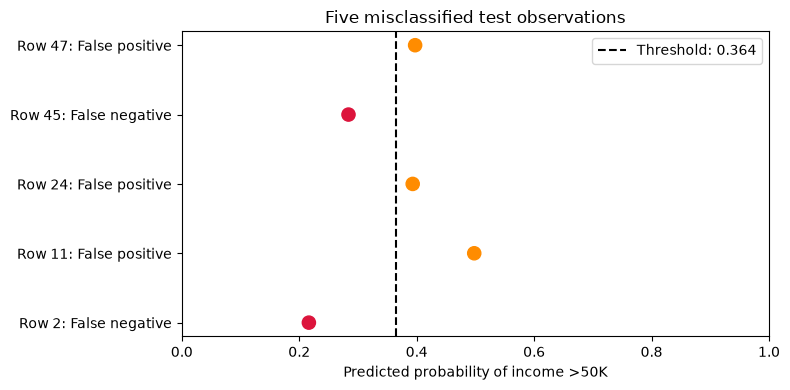

In [37]:
import matplotlib.pyplot as plt

slice_data["probability"] = np.asarray(test_probs)

# First five errors in file order: reproducible selection.
errors = slice_data.loc[
    slice_data["actual"] != slice_data["predicted"]
].head(5).copy()

errors["error_type"] = np.where(
    errors["actual"] == 0, "False positive", "False negative"
)

display(errors[[
    "age", "education-num", "capital-gain",
    "workclass", "sex", "actual", "predicted",
    "probability", "error_type",
]].round(4))

fig, ax = plt.subplots(figsize=(8, 4))

ax.scatter(
    errors["probability"],
    np.arange(len(errors)),
    c=errors["actual"].map({0: "darkorange", 1: "crimson"}),
    s=90,
)

ax.axvline(
    final_threshold,
    color="black",
    linestyle="--",
    label=f"Threshold: {final_threshold:.3f}",
)

ax.set_yticks(
    np.arange(len(errors)),
    [f"Row {idx}: {kind}"
     for idx, kind in zip(errors.index, errors["error_type"])],
)
ax.set_xlim(0, 1)
ax.set_xlabel("Predicted probability of income >50K")
ax.set_title("Five misclassified test observations")
ax.legend()
plt.tight_layout()
plt.show()